# Encontro 3 — Python II: grades, tabelas, mapas vetoriais e raster

**Modelagem Dinâmica Espacial · LambdaGeo/UFMA**

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lambdageo-edu/curso-modelagem-dinamica-espacial/blob/main/docs/notebooks/encontro03_python_dados_espaciais.ipynb)

Sem Python instalado? O selo acima abre este notebook no Google Colab, no navegador. Lá, use *Arquivo → Salvar uma cópia no Drive* antes de mudar qualquer coisa: sem a cópia, o que você escrever se perde ao fechar a página.

No encontro 2 os dados eram números soltos e listas. Hoje usamos as quatro bibliotecas que carregam os dados de qualquer modelo espacial:

| Biblioteca | Guarda | Exemplo de hoje |
|---|---|---|
| NumPy | matrizes (grades de números) | uma grade de classes de uso |
| pandas | tabelas | focos de queimada no Maranhão |
| GeoPandas | tabelas com geometria (vetor) | os estados do Brasil |
| rasterio | imagens georreferenciadas (raster) | o MapBiomas da Ilha do Maranhão |

🔧 = troque um valor e rode de novo; ✏️ = responda.

## 0. Preparação

In [1]:
import sys
if "google.colab" in sys.modules:    # no Colab, instala o que falta; no laboratório já está instalado
    %pip install -q rasterio

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

## 1. NumPy: a grade como matriz

Um mapa raster é uma **matriz**: linhas e colunas de números. Cada número é o valor de uma célula (pixel). Abaixo, uma grade de 6 × 8 células com códigos de classe do MapBiomas: 3 = floresta, 15 = pastagem, 33 = água.

In [2]:
grade = np.array([
    [ 3,  3,  3,  3, 15, 15, 33, 33],
    [ 3,  3,  3, 15, 15, 15, 33, 33],
    [ 3,  3, 15, 15, 15,  3, 33, 33],
    [ 3,  3, 15, 15,  3,  3,  3, 33],
    [ 3,  3,  3, 15,  3,  3,  3, 33],
    [ 3,  3,  3,  3,  3,  3, 33, 33],
])
print("forma (linhas, colunas):", grade.shape)
print("número de células:", grade.size)

forma (linhas, colunas): (6, 8)
número de células: 48


In [3]:
print("célula da linha 0, coluna 4:", grade[0, 4])
print("linha 2 inteira:", grade[2, :])
print("coluna 6 inteira:", grade[:, 6])

célula da linha 0, coluna 4: 15
linha 2 inteira: [ 3  3 15 15 15  3 33 33]
coluna 6 inteira: [33 33 33  3  3 33]


A operação mais útil: uma **comparação** feita na grade inteira de uma vez devolve outra grade, de verdadeiro/falso (uma *máscara*). Somar a máscara conta as células verdadeiras.

In [4]:
floresta = grade == 3
print(floresta.astype(int))
print("células de floresta:", floresta.sum())
print(f"fração de floresta: {floresta.mean():.0%}")

[[1 1 1 1 0 0 0 0]
 [1 1 1 0 0 0 0 0]
 [1 1 0 0 0 1 0 0]
 [1 1 0 0 1 1 1 0]
 [1 1 1 0 1 1 1 0]
 [1 1 1 1 1 1 0 0]]
células de floresta: 27
fração de floresta: 56%


In [5]:
codigos, contagens = np.unique(grade, return_counts=True)
for c, n in zip(codigos, contagens):
    print(f"classe {c:2d}: {n:2d} células")

classe  3: 27 células
classe 15: 11 células
classe 33: 10 células


Sem laço nenhum: NumPy aplica a conta a todas as células. É o que torna rápidos os modelos em raster (encontro 6).

Se cada célula tiver 30 m × 30 m, a área de cada classe sai de uma multiplicação:

In [6]:
area_celula_km2 = 30 * 30 / 1e6
print(f"pastagem: {(grade == 15).sum() * area_celula_km2:.4f} km²")

pastagem: 0.0099 km²


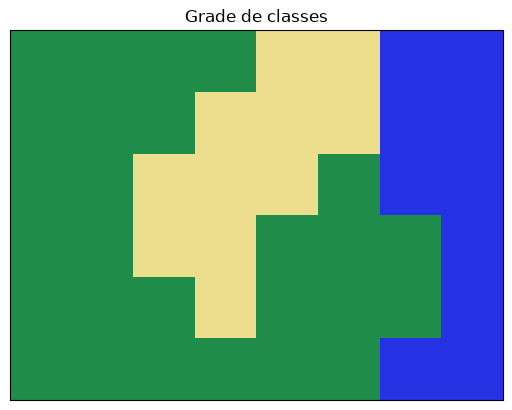

In [7]:
cores = ListedColormap(["#1f8d49", "#edde8e", "#2532e4"])          # floresta, pastagem, água
indices = np.select([grade == 3, grade == 15, grade == 33], [0, 1, 2])  # código → posição da cor
plt.imshow(indices, cmap=cores, vmin=0, vmax=2)
plt.title("Grade de classes"); plt.xticks([]); plt.yticks([]);

✏️ **Pergunta 1.** 🔧 Mude a célula da linha 0, coluna 0 para pastagem (`grade[0, 0] = 15`) e rode as contagens de novo. Quantas células de floresta restam?

## 2. pandas: tabelas

Uma tabela do pandas (*DataFrame*) tem colunas com nome, como uma planilha. Vamos ler os focos de queimada detectados por satélite no Maranhão em 5 e 6 de setembro de 2026, do BDQueimadas (INPE), guardados no repositório do livro *Geospatial Modeling with Python*.

O endereço aponta para uma versão fixa (o código longo no meio é o *commit*): quem rodar daqui a um ano lê exatamente o mesmo arquivo.

In [8]:
URL_QUEIMADAS = "https://raw.githubusercontent.com/LambdaGeo/geospatial-modeling-python/6902d721c8eefbe5246c6d74b3fb01a57b3fe1e1/docs/part2/bdqueimadas_ma.csv"
focos = pd.read_csv(URL_QUEIMADAS)
print(focos.shape, "(linhas, colunas)")
focos.head()

(1260, 6) (linhas, colunas)


,DataHora,Municipio,Bioma,Latitude,Longitude,FRP
0,2026/09/05 00:00:00,BARRA DO CORDA,Cerrado,-5.7756,-45.082600,120.4
1,2026/09/05 00:00:00,BARRA DO CORDA,Cerrado,-5.7571,-45.061300,60.7
2,2026/09/05 00:00:00,BARRA DO CORDA,Cerrado,-5.7758,-45.059900,163.3
3,2026/09/05 00:08:00,MIRADOR,Cerrado,-6.5542,-44.768902,NaN
4,2026/09/05 00:08:00,BARRA DO CORDA,Cerrado,-5.7686,-45.065498,NaN


Cada linha é um foco: data e hora, município, bioma, posição e FRP (potência radiativa do fogo, em megawatts, uma medida da intensidade). Algumas operações básicas:

In [9]:
print(focos.columns.tolist())
focos["FRP"].describe()

['DataHora', 'Municipio', 'Bioma', 'Latitude', 'Longitude', 'FRP']


count    1119.000000
mean       35.946470
std        58.543456
min         0.400000
25%         3.700000
50%         8.300000
75%        59.800000
max       516.200000
Name: FRP, dtype: float64

In [10]:
focos["Bioma"].value_counts()

Bioma
Cerrado     1092
Amazônia     167
Caatinga       1
Name: count, dtype: int64

**Filtrar** linhas por uma condição usa a mesma ideia de máscara do NumPy:

In [11]:
cerrado = focos[focos["Bioma"] == "Cerrado"]
print(len(cerrado), "focos no Cerrado")
fortes = focos[focos["FRP"] > 100]
print(len(fortes), "focos com FRP acima de 100 MW")

1092 focos no Cerrado
118 focos com FRP acima de 100 MW


**Agrupar** conta ou resume por categoria. Os dez municípios com mais focos:

In [12]:
por_municipio = focos.groupby("Municipio").agg(focos=("FRP", "size"), frp_medio=("FRP", "mean"))
top10 = por_municipio.sort_values("focos", ascending=False).head(10)
top10

,focos,frp_medio
Municipio,,
BARRA DO CORDA,110,51.287912
ALTO PARNAÍBA,64,11.407813
SANTA QUITÉRIA DO MARANHÃO,60,90.013793
SANTA LUZIA,55,43.334884
GOVERNADOR LUIZ ROCHA,52,148.505000
SÃO DOMINGOS DO MARANHÃO,50,75.641860
BALSAS,44,18.218182
FORMOSA DA SERRA NEGRA,36,28.356250
GRAJAÚ,35,36.987097


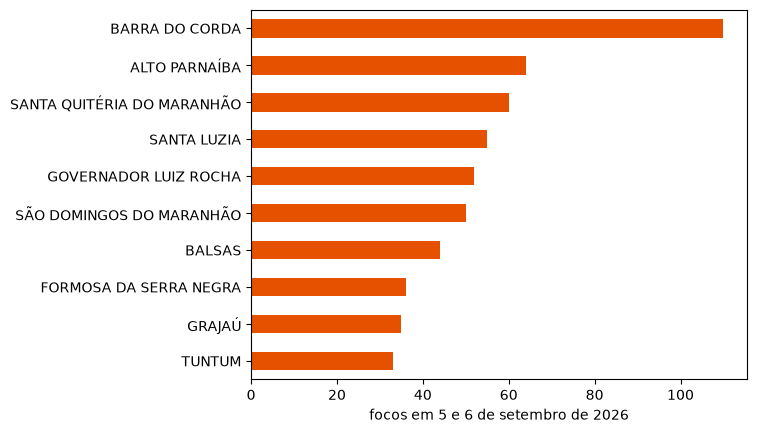

In [13]:
top10["focos"].sort_values().plot.barh(color="#e65100")
plt.xlabel("focos em 5 e 6 de setembro de 2026"); plt.ylabel("");

✏️ **Pergunta 2.** Qual município tem o maior FRP médio entre os dez? Mais focos significa fogo mais intenso?

## 3. GeoPandas: mapas vetoriais

Um *GeoDataFrame* é uma tabela do pandas com uma coluna a mais, `geometry`, que guarda pontos, linhas ou polígonos. Lemos os limites dos estados do Brasil (IBGE), do repositório do livro *Introdução ao Geoprocessamento e Sensoriamento Remoto*. O GeoPandas lê o shapefile direto do arquivo zip.

In [14]:
URL_UFS = "https://raw.githubusercontent.com/lambdageo-edu/book-geoprocessamento-e-sensoriamento-remoto/f1531f2aaba8c86d1a9a79c1eae9880f029c4648/docs/dados/BR_UF.zip"
ufs = gpd.read_file(URL_UFS)
print(ufs.crs)
ufs[["SIGLA_UF", "NM_UF", "NM_REGIAO", "AREA_KM2"]].head()

EPSG:4674


,SIGLA_UF,NM_UF,NM_REGIAO,AREA_KM2
0,AC,Acre,Norte,164173.429
1,AM,Amazonas,Norte,1559255.881
2,PA,Pará,Norte,1245870.704
3,AP,Amapá,Norte,142470.762
4,TO,Tocantins,Norte,277423.627


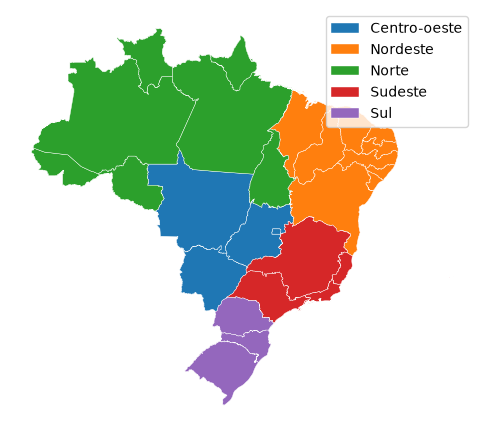

In [15]:
ax = ufs.plot(column="NM_REGIAO", legend=True, figsize=(6, 6), edgecolor="white", linewidth=0.3)
ax.set_axis_off();

In [16]:
maranhao = ufs[ufs["SIGLA_UF"] == "MA"]
print(f"área do Maranhão: {maranhao['AREA_KM2'].iloc[0]:,.0f} km²")

área do Maranhão: 329,651 km²


A tabela de focos tem latitude e longitude, mas não geometria. Transformamos cada linha num **ponto** e desenhamos sobre o estado:

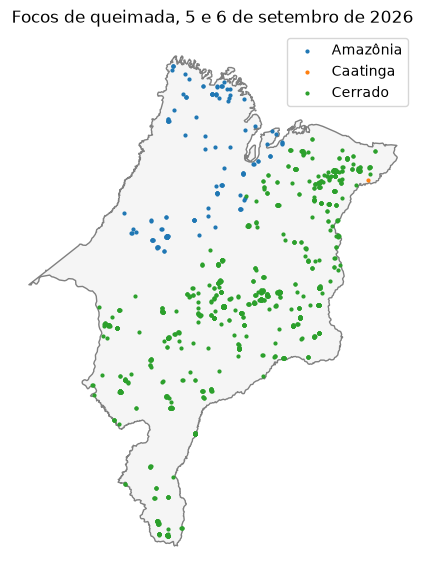

In [17]:
pontos = gpd.GeoDataFrame(focos, geometry=gpd.points_from_xy(focos["Longitude"], focos["Latitude"]),
                          crs="EPSG:4674")          # mesmo sistema de coordenadas dos estados (SIRGAS 2000)

ax = maranhao.plot(color="#f5f5f5", edgecolor="gray", figsize=(6, 7))
pontos.plot(ax=ax, column="Bioma", markersize=4, legend=True)
ax.set_title("Focos de queimada, 5 e 6 de setembro de 2026"); ax.set_axis_off();

✏️ **Pergunta 3.** Onde se concentram os focos? Compare com o que a tabela de biomas mostrou.

## 4. rasterio: o MapBiomas da Ilha do Maranhão

O MapBiomas publica um mapa de uso e cobertura do Brasil inteiro por ano, com pixels de 30 m: um único arquivo com mais de 10 bilhões de pixels. Não é preciso baixá-lo: o rasterio lê **só a janela** que interessa, direto do servidor.

As células desta parte precisam de internet. Sem rede, use o recorte salvo pela última célula (`mapbiomas_ilha_2024.tif`), que o professor distribui.

In [ ]:
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds

ANO = 2024
URL_MAPBIOMAS = ("https://storage.googleapis.com/mapbiomas-public/initiatives/brasil/collection11/"
                 f"lulc/coverage/brazil_coverage/brazil_coverage-col11_{ANO}.tif")
ILHA = (-44.45, -2.80, -43.95, -2.45)        # oeste, sul, leste, norte, em graus

with rasterio.open(URL_MAPBIOMAS) as fonte:
    print("Brasil inteiro:", fonte.width, "×", fonte.height, "pixels;", fonte.crs)
    janela = from_bounds(*transform_bounds("EPSG:4326", fonte.crs, *ILHA), transform=fonte.transform)
    janela = janela.round_offsets().round_lengths()
    classes = fonte.read(1, window=janela)
    transformacao = fonte.window_transform(janela)
    crs = fonte.crs

print("recorte da Ilha:", classes.shape, "pixels")

`classes` agora é uma matriz do NumPy como a da Parte 1, só que com cerca de 2,5 milhões de células. Contamos os pixels de cada classe e convertemos em área. Os nomes vêm da legenda da Coleção 11 (só as classes mais comuns; para as demais, consulte a [legenda oficial](https://brasil.mapbiomas.org/codigos-de-legenda/)).

In [ ]:
LEGENDA = {3: "Formação Florestal", 4: "Formação Savânica", 5: "Mangue", 9: "Silvicultura",
           11: "Campo Alagado e Área Pantanosa", 12: "Formação Campestre", 15: "Pastagem",
           21: "Mosaico de Usos", 23: "Praia, Duna e Areal", 24: "Área Urbanizada",
           25: "Outras Áreas não Vegetadas", 32: "Apicum", 33: "Rio, Lago e Oceano"}

codigos, contagens = np.unique(classes, return_counts=True)
tabela = pd.DataFrame({"código": codigos, "pixels": contagens})
tabela = tabela[tabela["código"] != 0]                       # 0 = sem dado
tabela["classe"] = tabela["código"].map(LEGENDA).fillna("outra (ver legenda)")
tabela["área (km²)"] = (tabela["pixels"] * 30 * 30 / 1e6).round(1)   # pixel de cerca de 30 × 30 m
tabela.sort_values("pixels", ascending=False)

In [ ]:
principais = tabela.sort_values("pixels", ascending=False)["código"].head(8).tolist()
mapa = np.full(classes.shape, len(principais))                # "outras" por padrão
for i, c in enumerate(principais):
    mapa[classes == c] = i
paleta = ListedColormap(plt.cm.tab10.colors[: len(principais)] + ((0.85, 0.85, 0.85),))

plt.figure(figsize=(9, 6))
plt.imshow(mapa, cmap=paleta, vmin=-0.5, vmax=len(principais) + 0.5)
barra = plt.colorbar(ticks=range(len(principais) + 1))
barra.ax.set_yticklabels([LEGENDA.get(c, str(c)) for c in principais] + ["outras"])
plt.title(f"MapBiomas Coleção 11, {ANO}: Ilha do Maranhão"); plt.xticks([]); plt.yticks([]);

Por fim, salvamos o recorte como GeoTIFF, para usar sem internet:

In [ ]:
perfil = {"driver": "GTiff", "dtype": classes.dtype, "count": 1, "crs": crs, "transform": transformacao,
          "width": classes.shape[1], "height": classes.shape[0], "compress": "deflate", "nodata": 0}
with rasterio.open(f"mapbiomas_ilha_{ANO}.tif", "w", **perfil) as destino:
    destino.write(classes, 1)

# Sem internet, comece por aqui:
# with rasterio.open("mapbiomas_ilha_2024.tif") as fonte:
#     classes = fonte.read(1)

✏️ **Pergunta 4.** Que classe ocupa mais área na Ilha, sem contar a água? A área da tabela é exata? (Dica: o pixel do MapBiomas tem 30 m na direção norte-sul, mas é definido em graus.)

## Para casa

1. 🔧 Troque `ANO` para 1985 e refaça a tabela. Quanto a Área Urbanizada cresceu entre 1985 e 2024?
2. Na tabela de focos, crie uma coluna `data` só com o dia (`focos["DataHora"].str[:10]`) e conte os focos por dia e por bioma (`groupby` com duas colunas).
3. Escolha outro estado no `ufs`, calcule quantos focos da tabela caem dentro dele (dica: `gpd.sjoin(pontos, estado)`) e explique o resultado.